In [1]:
# import packages
import pandas as pd
import numpy as np
import ast
import os
import requests
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import make_scorer, fbeta_score, precision_score, recall_score, f1_score, average_precision_score


In [3]:
# construct the API request
load_dotenv()
request_params = {
    'api_key': os.getenv('API_KEY'),
    'limit': 4000
}

api_url = 'https://developer.nps.gov/api/v1/thingstodo'
response = requests.get(api_url, params = request_params)

# check the API response
if response.status_code == 200:
    todo_data = response.json()
else:
    print(f'Response Code: {response.status_code}')
    print(f'Error Message: {response.text}')
    raise ValueError('Unsuccessful Request')


In [4]:
# save the data
selected_columns = [
    'doFeesApply',
    'isReservationRequired',
    'arePetsPermitted', 
    'tags', 
    'topics',   
    'timeOfDay',  
    'season',  
    'relatedParks',  
]

raw_todo_df = pd.DataFrame(todo_data['data'])
raw_todo_df.to_csv('../data/raw_todo.csv', index = False)
selected_todo_df = raw_todo_df[selected_columns].copy()
selected_todo_df.to_csv('../data/selected_todo.csv', index = False)


In [5]:
# count missing values for each column
for col in selected_todo_df.columns:
    if selected_todo_df[col].dtype == 'object':
        missing_count = sum(selected_todo_df[col].astype(str) == '[]')
        print(f'{col}: {missing_count} missing values')
    else:
        missing_count = sum(selected_todo_df[col] == '')
        print(f'{col}: {missing_count} missing values')

doFeesApply: 0 missing values
isReservationRequired: 0 missing values
arePetsPermitted: 0 missing values
tags: 338 missing values
topics: 0 missing values
timeOfDay: 801 missing values
season: 544 missing values
relatedParks: 112 missing values


In [6]:
eda_todo_df = selected_todo_df.copy()

# convert tags and topics to their lengths
for col in ['tags', 'topics']:
    eda_todo_df[col] = eda_todo_df[col].apply(lambda x: len(x) if isinstance(x, list) else 0)


In [7]:
# extract states from relatedParks and map to regions
region_map = {
    # Northeast 
    'CT': 'Northeast', 'ME': 'Northeast', 'MA': 'Northeast', 'NH': 'Northeast', 
    'RI': 'Northeast', 'VT': 'Northeast', 'NJ': 'Northeast', 'NY': 'Northeast', 'PA': 'Northeast',
    
    # Midwest 
    'IL': 'Midwest', 'IN': 'Midwest', 'MI': 'Midwest', 'OH': 'Midwest', 'WI': 'Midwest',
    'IA': 'Midwest', 'KS': 'Midwest', 'MN': 'Midwest', 'MO': 'Midwest', 'NE': 'Midwest', 
    'ND': 'Midwest', 'SD': 'Midwest',
    
    # South 
    'DE': 'South', 'DC': 'South', 'FL': 'South', 'GA': 'South', 'MD': 'South', 
    'NC': 'South', 'SC': 'South', 'VA': 'South', 'WV': 'South', 'AL': 'South', 
    'KY': 'South', 'MS': 'South', 'TN': 'South', 'AR': 'South', 'LA': 'South', 
    'OK': 'South', 'TX': 'South',
    
    # West 
    'AZ': 'West', 'CO': 'West', 'ID': 'West', 'MT': 'West', 'NV': 'West', 
    'NM': 'West', 'UT': 'West', 'WY': 'West', 'AK': 'West', 'CA': 'West', 
    'HI': 'West', 'OR': 'West', 'WA': 'West',

    # Territories 
    'PR': 'Territories', 
    'VI': 'Territories', 
    'GU': 'Territories', 
    'AS': 'Territories', 
    'MP': 'Territories'  
}

eda_todo_df['regions'] = eda_todo_df['relatedParks'].apply(
    lambda val: sorted({
        region_map[state.strip()]
        for park in (val or [])       
        for state in str(park.get('states', '')).split(',')
    })
)


In [8]:
# extract designations from relatedParks and categorize parks
eda_todo_df['designations'] = eda_todo_df['relatedParks'].apply(
    lambda val: sorted({
        park.get('designation')
        for park in (val or [])
        if park.get('designation')  
    })
)

def categorize_park(name):
    name = str(name).strip()

    if name in [
        'National Park', 'National Parks',
        'National and State Parks', 'National Park & Preserve'
    ]:
        return 'National_Park'
    
    elif any(x in name for x in [
        'Historical', 'Historic', 'International Historic'
    ]):
        return 'Historical_Site'
    
    elif any(x in name for x in [
        'Monument', 'Memorial', 'Battlefield', 'Military Park'
    ]):
        return 'National_Monument'
    
    elif any(x in name for x in [
        'Recreation', 'Parkway', 'Lakeshore', 'Seashore'
    ]):
        return 'Recreation_Area'
    
    else:
        return 'Other_Protected_Area'


eda_todo_df['park_categories'] = eda_todo_df['designations'].apply(
    lambda des_list: sorted({
        categorize_park(des)        
        for des in (des_list or [])
    })
)



In [9]:
# convert columns to string type
for col in ['timeOfDay', 'season', 'regions', 'park_categories']:
    eda_todo_df[col] = eda_todo_df[col].astype(str)

# convert boolean columns to True/False
for col in ['isReservationRequired', 'arePetsPermitted', 'doFeesApply']:
    eda_todo_df[col] = eda_todo_df[col].map({'true': True, 'false': False})



In [10]:
# drop the original columns and save the EDA dataframe to a CSV file
eda_todo_df = eda_todo_df.drop(columns = ['relatedParks', 'designations'])
eda_todo_df.to_csv('../data/eda_todo.csv', index = False)

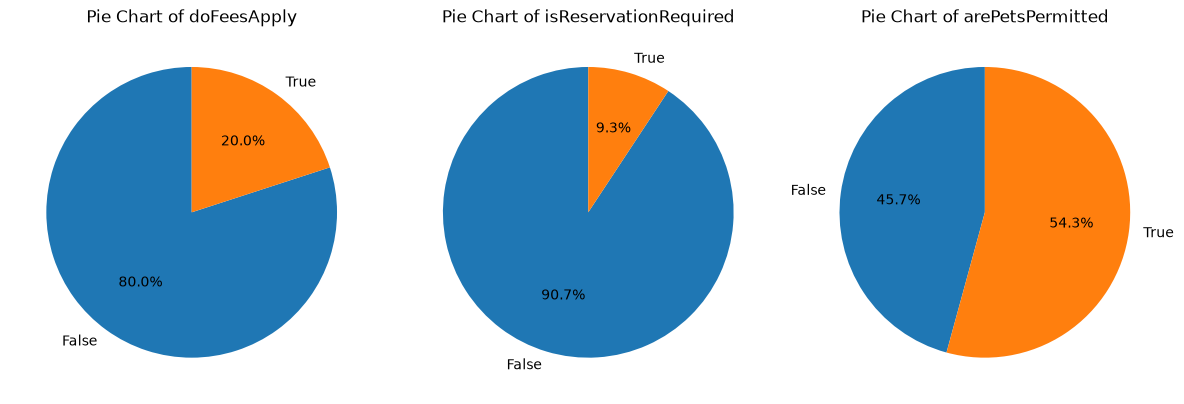

In [11]:
# create pie charts for doFeesApply, isReservationRequired, and arePetsPermitted
pie_cols = ['doFeesApply', 'isReservationRequired', 'arePetsPermitted']

fig, axes = plt.subplots(1, 3, figsize = (12, 6))
for ax, col in zip(axes, pie_cols):
   counts = eda_todo_df[col].value_counts().sort_index()
   ax.pie(counts, labels = counts.index, autopct = '%1.1f%%', startangle = 90)
   ax.set_title(f'Pie Chart of {col}')

plt.savefig('../figures/pie_charts.png', dpi = 150, bbox_inches = 'tight')
plt.tight_layout()
plt.show()

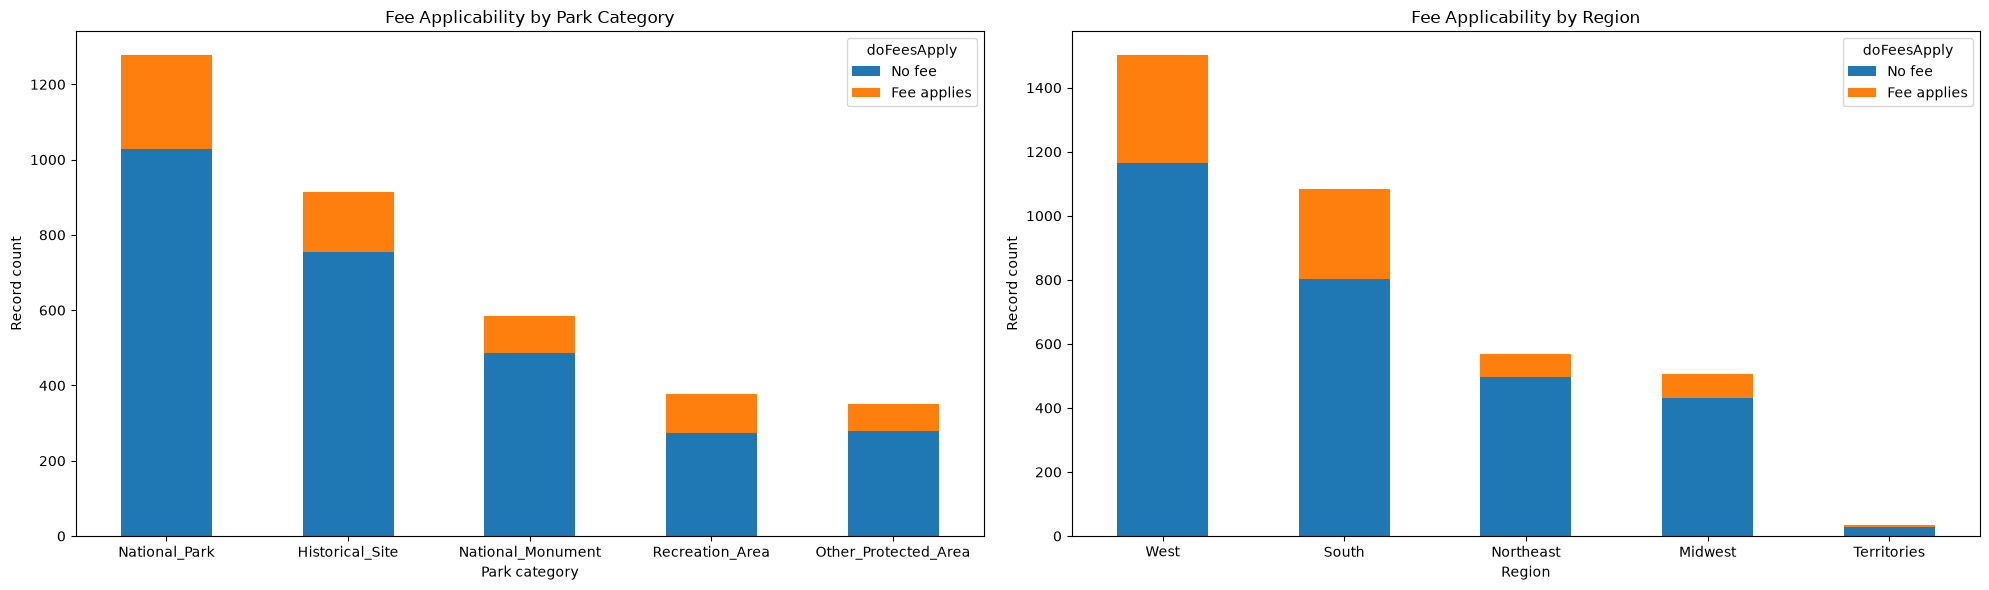

In [12]:
# Draw the stacked bar plot between each park category (left) / region (right) and fee requirement
park_categories = ['National_Park', 'Historical_Site', 'National_Monument', 'Recreation_Area', 'Other_Protected_Area']
regions = ['West', 'South', 'Northeast', 'Midwest', 'Territories']

def fee_counts_by_label(column, labels):
    parsed = eda_todo_df[column].apply(
        lambda value: ast.literal_eval(value)
        if isinstance(value, str) and value.strip()
        else value if isinstance(value, (list, tuple, set)) else []
    )
    return pd.DataFrame(
            {
                name: [
                    ((eda_todo_df["doFeesApply"].eq(fee)) & parsed.apply(lambda values: label in values)).sum()
                    for label in labels
                ]
                for fee, name in [(False, 'No fee'), (True, 'Fee applies')]
            },
            index = labels,
        )

park_counts = fee_counts_by_label('park_categories', park_categories)
region_counts = fee_counts_by_label('regions', regions)

fig, axes = plt.subplots(1, 2, figsize = (20, 6))

for ax, counts, title, xlabel in [
    (axes[0], park_counts, 'Fee Applicability by Park Category', 'Park category'),
    (axes[1], region_counts, 'Fee Applicability by Region', 'Region')
]:
    counts.plot(
        kind = 'bar', stacked = True, ax = ax, legend = False,
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Record count')
    ax.tick_params(axis = 'x', rotation = 0)

axes[0].legend(title = 'doFeesApply')
axes[1].legend(title = 'doFeesApply')

plt.savefig('../figures/fee_applicability.png', dpi = 150, bbox_inches = 'tight')
fig.tight_layout()
plt.show()

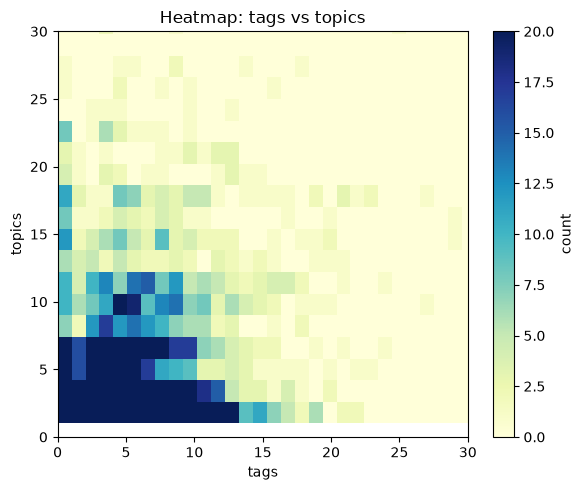

In [13]:
# Create a heatmap to visualize the relationship between tags and topics
nbins = 50  
heatmap, xedges, yedges = np.histogram2d(eda_todo_df['tags'], eda_todo_df['topics'], bins = nbins)

plt.figure(figsize = (6, 5))

plt.imshow(heatmap.T, origin = 'lower', aspect = 'auto', cmap = 'YlGnBu', vmax = 20, 
           extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]])

plt.colorbar(label = 'count')
plt.xlabel('tags')
plt.ylabel('topics')
plt.title('Heatmap: tags vs topics')
plt.xlim(0, 30)
plt.ylim(0, 30)

plt.savefig('../figures/heatmap.png', dpi = 150, bbox_inches = 'tight')
plt.tight_layout()
plt.show()

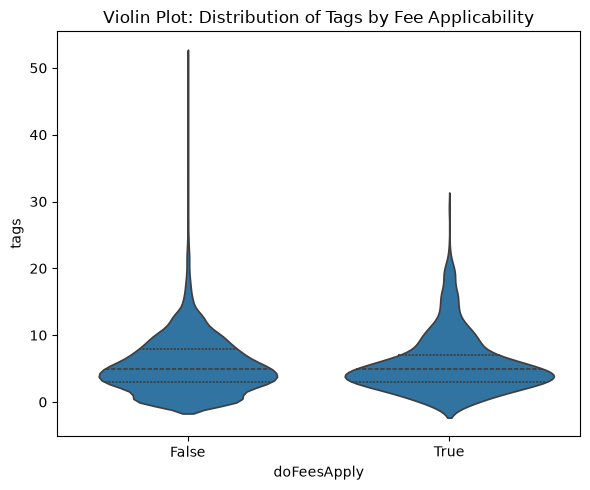

In [14]:
# Create a violin plot to visualize the distribution of tags based on fee applicability
plt.figure(figsize = (6, 5))
sns.violinplot(data = eda_todo_df, x = 'doFeesApply', y = 'tags', inner = 'quartile')
plt.title('Violin Plot: Distribution of Tags by Fee Applicability')

plt.savefig('../figures/violinplot.png', dpi = 150, bbox_inches = 'tight')
plt.tight_layout()
plt.show()

In [2]:


eda_todo_df=pd.read_csv('eda_todo.csv')


clean_todo_df = eda_todo_df.copy()

# Convert True/False to 1/0
for col in ['isReservationRequired', 'arePetsPermitted', 'doFeesApply']:
    clean_todo_df[col] = clean_todo_df[col].astype(int)

# Replace empty lists with indicator labels
for col in ['timeOfDay', 'season', 'regions', 'park_categories']:
    clean_todo_df[col] = clean_todo_df[col].apply(
        lambda x: ast.literal_eval(x) if isinstance(x, str) else x
    )
    clean_todo_df[col] = clean_todo_df[col].apply(
        lambda x: [f'{col}_Empty'] if len(x) == 0 else x
    )


In [3]:
# Define a custom transformer for MultiLabelBinarizer to handle multiple columns
class MultiLabelBinarizerTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y = None):
        self.mlbs_ = [
            MultiLabelBinarizer().fit(X[col])
            for col in X.columns
        ]
        return self

    def transform(self, X):
        return np.hstack([
            mlb.transform(X[col])
            for mlb, col in zip(self.mlbs_, X.columns)
        ])

In [4]:
# Prepare the data for modeling
X = clean_todo_df.drop(columns = ['doFeesApply'])
y = clean_todo_df['doFeesApply']
std_ftrs = ['tags', 'topics']
multilabel_ftrs = ['timeOfDay', 'season', 'regions', 'park_categories']

preprocessor = ColumnTransformer(
    transformers = [
        ('std', StandardScaler(), std_ftrs),
        ('multilabel', MultiLabelBinarizerTransformer(), multilabel_ftrs)],
        remainder = 'passthrough')


In [5]:
# Define a function to perform Stratified K-Fold cross-validation with F1 score evaluation

def MLpipe_StratifiedKFold_F1(X, y, preprocessor, ML_algo, param_grid):

    cv_scores = []
    best_params_list = []
    best_models = []
    test_sets = []

    for rs in range(5):
        X_other, X_test, y_other, y_test = train_test_split(X, y, test_size = 0.2, stratify=y, random_state = rs)
        kf = StratifiedKFold(n_splits = 5, shuffle = True, random_state = rs)
        pipe = Pipeline(steps = [('preprocessor', preprocessor), ('model', ML_algo)])
        grid = GridSearchCV(pipe, param_grid = param_grid, scoring = make_scorer(f1_score), cv = kf)
        grid.fit(X_other, y_other)
        cv_scores.append(grid.best_score_)
        best_params = {k: float(v) if isinstance(v, np.floating) else v
                       for k, v in grid.best_params_.items()}
        best_params_list.append(best_params)
        best_models.append(grid.best_estimator_)
        test_sets.append((X_test, y_test))


    CV_results_df = pd.DataFrame({'CV F1': cv_scores, 'Best Params': best_params_list})
    CV_results_df.index.name = 'Random State'
    CV_summary_df = pd.DataFrame({'Mean': [np.mean(cv_scores)], 'Std': [np.std(cv_scores)]}, index = ['CV F1'])
        
    return CV_results_df, CV_summary_df, best_models, test_sets

In [6]:
# %%
# Baseline: Always predict 1 using MLpipe_StratifiedKFold_F1
from sklearn.dummy import DummyClassifier

baseline_grid = {}

baseline_CV_results_df, baseline_CV_summary_df, baseline_best_models, baseline_test_sets = MLpipe_StratifiedKFold_F1(
    X,
    y,
    preprocessor,
    DummyClassifier(strategy="constant", constant=1),
    baseline_grid,
)
print(baseline_CV_results_df)
print(baseline_CV_summary_df)

                 CV F1 Best Params
Random State                      
0             0.333235          {}
1             0.333235          {}
2             0.333235          {}
3             0.333235          {}
4             0.333235          {}
           Mean  Std
CV F1  0.333235  0.0


In [14]:

# %%
# Fit the Logistic Regression Model
from sklearn.linear_model import LogisticRegression

lr_grid = {
    "model__C": np.logspace(-3, 3, 13),
    "model__l1_ratio": [1.0, 0.75, 0.5, 0.25, 0.0],
    "model__solver": ["saga"],
    "model__max_iter": [2000],
    "model__class_weight": [None, "balanced"]
}

lr_CV_results_df, lr_CV_summary_df, lr_best_models, lr_test_sets = MLpipe_StratifiedKFold_F1(
    X, y, preprocessor, LogisticRegression(random_state=42), lr_grid
)
print(lr_CV_results_df)
print(lr_CV_summary_df)

                 CV F1                                        Best Params
Random State                                                             
0             0.493174  {'model__C': 0.03162277660168379, 'model__clas...
1             0.500483  {'model__C': 0.31622776601683794, 'model__clas...
2             0.499245  {'model__C': 0.03162277660168379, 'model__clas...
3             0.494013  {'model__C': 0.03162277660168379, 'model__clas...
4             0.509339  {'model__C': 1.0, 'model__class_weight': 'bala...
           Mean      Std
CV F1  0.499251  0.00579


In [15]:
# Fit the SVC model

ML_algo = SVC(class_weight = 'balanced', random_state = 42)
param_grid = {'model__C': np.logspace(0, 4, 8), 'model__gamma': [1e-2, 1e-1, 1e0, 1e1, 1e2]}

svc_CV_results_df, svc_CV_summary_df, svc_best_models, svc_test_sets = MLpipe_StratifiedKFold_F1(X, y, preprocessor, ML_algo, param_grid)
print(svc_CV_results_df)
print(svc_CV_summary_df)

                 CV F1                                        Best Params
Random State                                                             
0             0.608844  {'model__C': 13.894954943731374, 'model__gamma...
1             0.617152  {'model__C': 3.72759372031494, 'model__gamma':...
2             0.604015             {'model__C': 1.0, 'model__gamma': 0.1}
3             0.626863             {'model__C': 1.0, 'model__gamma': 0.1}
4             0.616310             {'model__C': 1.0, 'model__gamma': 0.1}
           Mean      Std
CV F1  0.614637  0.00781


In [16]:
# Fit the Random Forest Model

from sklearn.ensemble import RandomForestClassifier

rf_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 15, 20, 25, 30],
    "model__min_samples_leaf": [1, 5, 10],
    "model__max_features": [1.0, "sqrt"],
    "model__class_weight": ["balanced", "balanced_subsample"]
}

ML_algo = RandomForestClassifier(random_state=42, n_jobs=1)
param_grid = rf_grid

rf_CV_results_df, rf_CV_summary_df, rf_best_models, rf_test_sets = MLpipe_StratifiedKFold_F1(X, y, preprocessor, ML_algo, param_grid)
print(rf_CV_results_df)
print(rf_CV_summary_df)

                 CV F1                                        Best Params
Random State                                                             
0             0.635290  {'model__class_weight': 'balanced', 'model__ma...
1             0.636918  {'model__class_weight': 'balanced', 'model__ma...
2             0.627809  {'model__class_weight': 'balanced_subsample', ...
3             0.637025  {'model__class_weight': 'balanced_subsample', ...
4             0.630718  {'model__class_weight': 'balanced', 'model__ma...
           Mean       Std
CV F1  0.633552  0.003672


In [17]:
# Fit the KNN Model

from sklearn.neighbors import KNeighborsClassifier

knn_grid = {
    "model__n_neighbors": [1, 3, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

# Results are assigned by the function call below.

knn_CV_results_df, knn_CV_summary_df, knn_best_models, knn_test_sets = MLpipe_StratifiedKFold_F1(X, y, preprocessor, KNeighborsClassifier(), knn_grid)
print(knn_CV_results_df)
print(knn_CV_summary_df)

d:\ANACONDA\envs\data1030\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


                 CV F1                                        Best Params
Random State                                                             
0             0.574220  {'model__n_neighbors': 3, 'model__p': 1, 'mode...
1             0.571103  {'model__n_neighbors': 3, 'model__p': 1, 'mode...
2             0.550312  {'model__n_neighbors': 3, 'model__p': 2, 'mode...
3             0.562364  {'model__n_neighbors': 3, 'model__p': 1, 'mode...
4             0.553379  {'model__n_neighbors': 1, 'model__p': 1, 'mode...
           Mean       Std
CV F1  0.562275  0.009412


In [18]:

from xgboost import XGBClassifier

# 1. Split X and y into non-test and test sets matching MLpipe_StratifiedKFold_F1 (test_size=0.2)
X_other, X_test, y_other, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 2. Split a small early-stopping validation set from X_other and y_other (without touching X_test)
X_tr, X_es, y_tr, y_es = train_test_split(
    X_other, y_other, test_size=0.15, stratify=y_other, random_state=42
)

# 3. Fit preprocessor and transform the early-stopping validation set for monitoring
prep_for_es = Pipeline([("preprocessor", preprocessor)])
prep_for_es.fit(X_tr, y_tr)
X_es_proc = prep_for_es.transform(X_es)

xgb_grid = {
    "model__n_estimators": [300],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
}

xgb_es_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss",
    early_stopping_rounds=50,
    n_jobs=1,
)

pipe_es = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_es_model),
])

cv_es = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_es = GridSearchCV(
    estimator=pipe_es,
    param_grid=xgb_grid,
    scoring=make_scorer(f1_score),
    cv=cv_es,
    n_jobs=1,
)

grid_es.fit(
    X_tr,
    y_tr,
    model__eval_set=[(X_es_proc, y_es)],
    model__verbose=False,
)

best_xgb = grid_es.best_estimator_.named_steps["model"]
best_n_estimators = int(getattr(best_xgb, "best_iteration", 100) + 1)
print("Best iteration count from early stopping:", best_n_estimators)
print("Best hyperparameters from early-stopping tuning:", grid_es.best_params_)

# 4. Pass the tuned hyperparameters and early-stopped n_estimators into MLpipe_StratifiedKFold_F1
tuned_xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss",
    n_jobs=1,
)

tuned_xgb_grid = {
    "model__n_estimators": [best_n_estimators],
    "model__max_depth": [grid_es.best_params_["model__max_depth"]],
    "model__learning_rate": [grid_es.best_params_["model__learning_rate"]],
    "model__subsample": [grid_es.best_params_["model__subsample"]],
    "model__colsample_bytree": [grid_es.best_params_["model__colsample_bytree"]],
}

xgb_CV_results_df, xgb_CV_summary_df, xgb_best_models, xgb_test_sets = MLpipe_StratifiedKFold_F1(
    X, y, preprocessor, tuned_xgb_model, tuned_xgb_grid
)
print(xgb_CV_results_df)
print(xgb_CV_summary_df)

Best iteration count from early stopping: 49
Best hyperparameters from early-stopping tuning: {'model__colsample_bytree': 1.0, 'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__n_estimators': 300, 'model__subsample': 0.8}
                 CV F1                                        Best Params
Random State                                                             
0             0.582380  {'model__colsample_bytree': 1.0, 'model__learn...
1             0.564449  {'model__colsample_bytree': 1.0, 'model__learn...
2             0.560672  {'model__colsample_bytree': 1.0, 'model__learn...
3             0.575633  {'model__colsample_bytree': 1.0, 'model__learn...
4             0.551230  {'model__colsample_bytree': 1.0, 'model__learn...
           Mean       Std
CV F1  0.566873  0.011011


In [20]:

# Combine all models (including Baseline) and sort by Mean CV F1 descending
summary_frames = {
    "Baseline (Always 1)": baseline_CV_summary_df,
    "Logistic Regression": lr_CV_summary_df,
    "SVC": svc_CV_summary_df,
    "Random Forest": rf_CV_summary_df,
    "KNN": knn_CV_summary_df,
    "XGBoost": xgb_CV_summary_df,
}

model_comparison_df = pd.DataFrame([
    {
        "Model": name,
        "CV F1 Mean": df.loc["CV F1", "Mean"],
        "CV F1 Std": df.loc["CV F1", "Std"],
    }
    for name, df in summary_frames.items()
]).sort_values(by="CV F1 Mean", ascending=False).reset_index(drop=True)

model_comparison_df.index = model_comparison_df.index + 1
model_comparison_df.index.name = "Rank"
print(model_comparison_df)

                    Model  CV F1 Mean  CV F1 Std
Rank                                            
1           Random Forest    0.633552   0.003672
2                     SVC    0.614637   0.007810
3                 XGBoost    0.566873   0.011011
4                     KNN    0.562275   0.009412
5     Logistic Regression    0.499251   0.005790
6     Baseline (Always 1)    0.333235   0.000000


In [21]:
# %%
# Evaluate F1, F2, Recall, PR-AUC (AP), and Precision on the test sets
winner_name = "Random Forest"  

models_dict = {
    "Random Forest": (rf_best_models, rf_test_sets),
    "SVC": (svc_best_models, svc_test_sets),
    "XGBoost": (xgb_best_models, xgb_test_sets),
    "KNN": (knn_best_models, knn_test_sets),
    "Logistic Regression": (lr_best_models, lr_test_sets),
}

winner_models, winner_test_sets = models_dict[winner_name]
test_results = []

for rs in range(5):
    best_model = winner_models[rs]
    X_test, y_test = winner_test_sets[rs]

    y_pred = best_model.predict(X_test)

    if hasattr(best_model, "predict_proba"):
        y_score = best_model.predict_proba(X_test)[:, 1]
    else:
        y_score = best_model.decision_function(X_test)

    test_results.append({
        "Test F1": f1_score(y_test, y_pred, zero_division=0),
        "Test F2": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
        "Test Recall": recall_score(y_test, y_pred, zero_division=0),
        "Test PR-AUC": average_precision_score(y_test, y_score),
        "Test Precision": precision_score(y_test, y_pred, zero_division=0),
    })

test_results_df = pd.DataFrame(test_results)
test_results_df.index.name = "Random State"

test_summary_df = pd.DataFrame({
    "Mean": test_results_df.mean(),
    "Std": test_results_df.std(ddof=0),
})

print(f"=== Test Evaluation for Best Model: {winner_name} ===")
print(test_results_df)
print(test_summary_df)

=== Test Evaluation for Best Model: Random Forest ===
               Test F1   Test F2  Test Recall  Test PR-AUC  Test Precision
Random State                                                              
0             0.664495  0.692935     0.713287     0.730146        0.621951
1             0.618893  0.645380     0.664336     0.683551        0.579268
2             0.641270  0.678763     0.706294     0.726530        0.587209
3             0.625000  0.627615     0.629371     0.688401        0.620690
4             0.647249  0.677507     0.699301     0.691446        0.602410
                    Mean       Std
Test F1         0.639381  0.016265
Test F2         0.664440  0.024113
Test Recall     0.682517  0.031461
Test PR-AUC     0.704015  0.020051
Test Precision  0.602306  0.017219


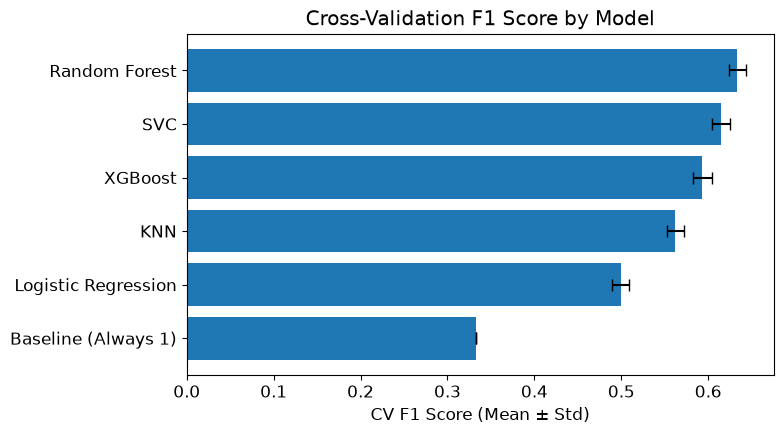

In [22]:


# Replace Mean and Std values with your exact CV summary results
df_plot = pd.DataFrame({
    "Model": [
        "Baseline (Always 1)",
        "Logistic Regression",
        "KNN",
        "XGBoost",
        "SVC",
        "Random Forest",
    ],
    "Mean": [0.3332, 0.4993, 0.5623, 0.5932, 0.6146, 0.6335],
    "Std":  [0.0000, 0.0100, 0.0100, 0.0110, 0.0100, 0.0100],
})

plt.rcParams.update({"font.size": 12})
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(df_plot["Model"], df_plot["Mean"], xerr=df_plot["Std"], capsize=4)
ax.set_xlabel("CV F1 Score (Mean ± Std)")
ax.set_title("Cross-Validation F1 Score by Model")
plt.tight_layout()
plt.show()

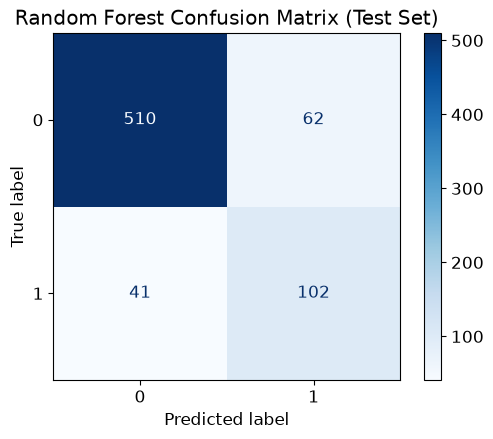

In [24]:

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Pick one fitted Random Forest pipeline and its corresponding test set (for example, random_state index 0)
best_rf_pipe = rf_best_models[0]
X_test_sample, y_test_sample = rf_test_sets[0]

y_pred = best_rf_pipe.predict(X_test_sample)
cm = confusion_matrix(y_test_sample, y_pred)

plt.rcParams.update({"font.size": 12})
fig, ax = plt.subplots(figsize=(5.5, 4.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(ax=ax, cmap="Blues", colorbar=True)
ax.set_title("Random Forest Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

In [30]:
for name, trans, cols in prep_step.transformers_:
    print("Transformer name:", name, "| cols:", cols, "| trans:", type(trans))
    if hasattr(trans, "steps"):
        for s_name, s_obj in trans.steps:
            print("   step:", s_name, "->", type(s_obj), "classes_:", getattr(s_obj, "classes_", None))

Transformer name: std | cols: ['tags', 'topics'] | trans: <class 'sklearn.preprocessing._data.StandardScaler'>
Transformer name: multilabel | cols: ['timeOfDay', 'season', 'regions', 'park_categories'] | trans: <class '__main__.MultiLabelBinarizerTransformer'>
Transformer name: remainder | cols: ['isReservationRequired', 'arePetsPermitted'] | trans: <class 'sklearn.preprocessing._function_transformer.FunctionTransformer'>


Top Permutation Importance (Raw Features):


,Feature,Permutation_Importance
6,regions,0.189874
0,isReservationRequired,0.170160
7,park_categories,0.113407
4,timeOfDay,0.109276
3,topics,0.088143
1,arePetsPermitted,0.086337
5,season,0.078500
2,tags,0.058811


Top Tree Impurity Importance (Preprocessed Features):


,Feature,Tree_Importance
0,tags,0.181436
1,topics,0.171099
24,isReservationRequired,0.120642
25,arePetsPermitted,0.054375
14,multilabel_12 (timeOfDay/season/regions/park_c...,0.042805
16,multilabel_14 (timeOfDay/season/regions/park_c...,0.038961
10,multilabel_8 (timeOfDay/season/regions/park_ca...,0.033026
20,multilabel_18 (timeOfDay/season/regions/park_c...,0.032378
18,multilabel_16 (timeOfDay/season/regions/park_c...,0.027365
22,multilabel_20 (timeOfDay/season/regions/park_c...,0.027172


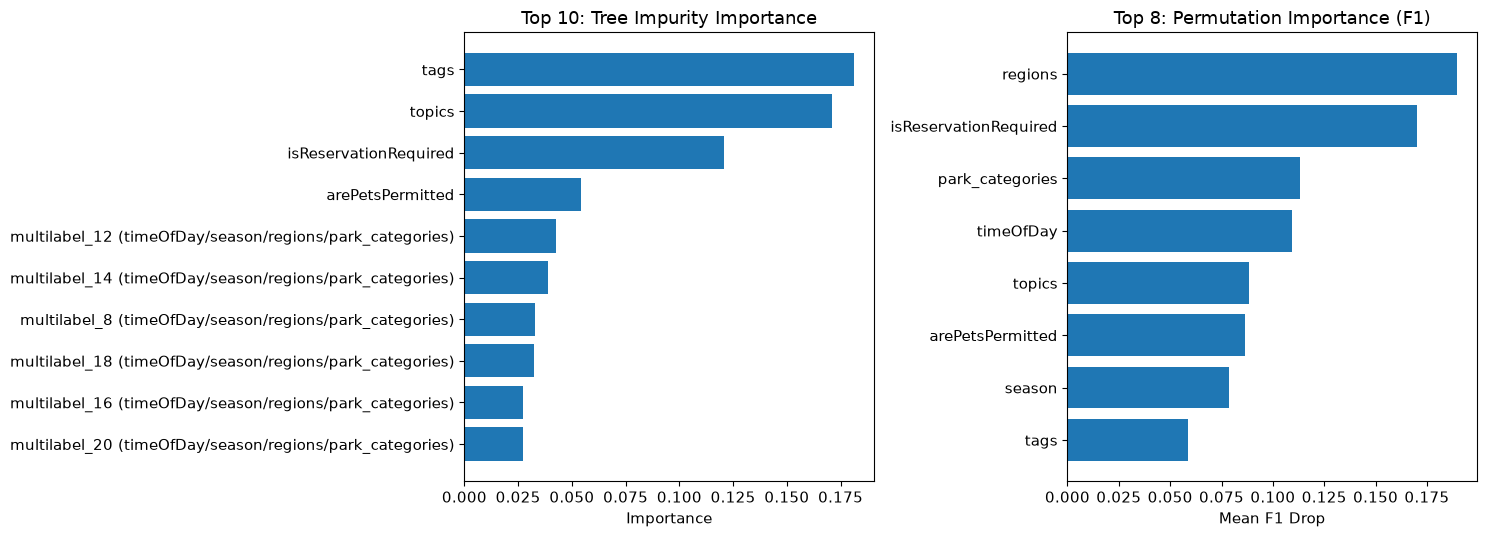

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance


def get_clean_feature_names(preprocessor, X_sample, expected_len):
    names = []
    for name, trans, cols in preprocessor.transformers_:
        col_list = (
            list(cols)
            if isinstance(cols, (list, np.ndarray, tuple, pd.Index))
            else [cols]
        )

        # Compute exact output column count for this transformer block
        part_out = trans.transform(X_sample[col_list])
        if hasattr(part_out, "toarray"):
            part_out = part_out.toarray()
        n_out = part_out.shape[1] if getattr(part_out, "ndim", 1) > 1 else 1

        if name == "std":
            if n_out == len(col_list):
                names.extend(col_list)
            else:
                names.extend([f"std_{i}" for i in range(n_out)])

        elif name == "remainder":
            if n_out == len(col_list):
                names.extend(col_list)
            else:
                names.extend([f"rem_{i}" for i in range(n_out)])

        elif name == "multilabel":
            # Try to extract class labels if stored inside the custom transformer
            sub_names = []
            for attr in ("classes_", "all_classes_", "columns_", "feature_names_"):
                val = getattr(trans, attr, None)
                if val is not None and len(val) == n_out:
                    sub_names = [f"multilabel__{c}" for c in val]
                    break

            if not sub_names and hasattr(trans, "__dict__"):
                for k, v in trans.__dict__.items():
                    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == n_out:
                        sub_names = [f"multilabel__{c}" for c in v]
                        break

            if not sub_names:
                sub_names = [f"multilabel_{i} ({'/'.join(col_list)})" for i in range(n_out)]

            names.extend(sub_names)

        else:
            if n_out == len(col_list):
                names.extend(col_list)
            else:
                names.extend([f"{name}_{i}" for i in range(n_out)])

    if len(names) != expected_len:
        return [f"feat_{i}" for i in range(expected_len)]
    return names


best_rf_pipe = rf_best_models[0]
X_test_sample, y_test_sample = rf_test_sets[0]

rf_est = best_rf_pipe.named_steps["model"]
prep_step = best_rf_pipe.named_steps["preprocessor"]

# 1. Permutation importance on raw input features
raw_feature_names = list(X_test_sample.columns)
perm_res = permutation_importance(
    best_rf_pipe,
    X_test_sample,
    y_test_sample,
    n_repeats=10,
    random_state=42,
    scoring="f1",
    n_jobs=1,
)
perm_df = pd.DataFrame({
    "Feature": raw_feature_names,
    "Permutation_Importance": perm_res.importances_mean,
}).sort_values("Permutation_Importance", ascending=False)

# 2. Tree-based (Gini / impurity) importance on preprocessed features
trans_feature_names = get_clean_feature_names(
    prep_step, X_test_sample, expected_len=len(rf_est.feature_importances_)
)

tree_df = pd.DataFrame({
    "Feature": trans_feature_names,
    "Tree_Importance": rf_est.feature_importances_,
}).sort_values("Tree_Importance", ascending=False)

print("Top Permutation Importance (Raw Features):")
display(perm_df.head(8))

print("Top Tree Impurity Importance (Preprocessed Features):")
display(tree_df.head(10))

# Plot side-by-side comparison
top_perm = perm_df.head(8).iloc[::-1]
top_tree = tree_df.head(10).iloc[::-1]

plt.rcParams.update({"font.size": 11})
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].barh(top_tree["Feature"], top_tree["Tree_Importance"])
axes[0].set_title("Top 10: Tree Impurity Importance")
axes[0].set_xlabel("Importance")

axes[1].barh(top_perm["Feature"], top_perm["Permutation_Importance"])
axes[1].set_title("Top 8: Permutation Importance (F1)")
axes[1].set_xlabel("Mean F1 Drop")

plt.tight_layout()
plt.show()

Top 10 Features by Mean Absolute SHAP (mlb_k = binarized sub-features from timeOfDay/season/regions/park_categories):


isReservationRequired    0.087758
topics                   0.049374
mlb_12                   0.045019
arePetsPermitted         0.041158
tags                     0.038697
mlb_14                   0.031010
mlb_0                    0.024019
mlb_4                    0.016590
mlb_11                   0.015843
mlb_18                   0.015122
dtype: float64

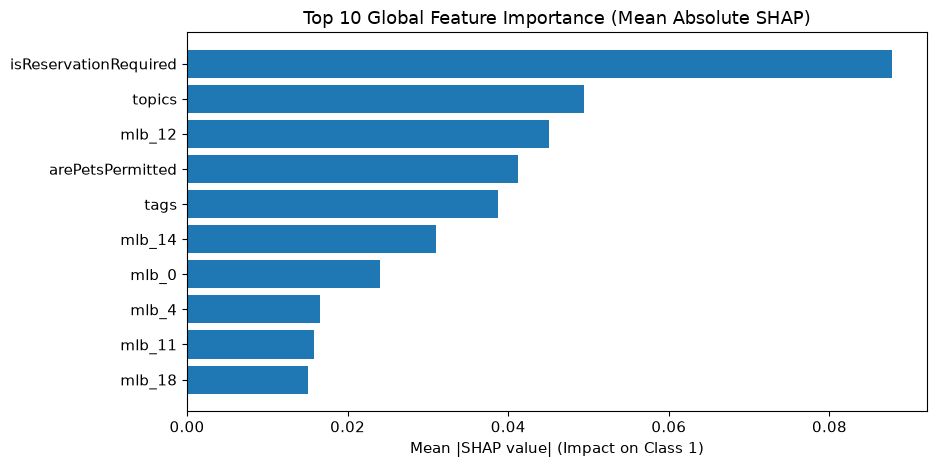

Sample Index: 0 | True Label: 0 | Predicted Class: 0 | Predicted Prob(1): 0.1749
SHAP Base Value (reference): 0.5002 | Sum of SHAP: -0.3254

Top features pushing prediction HIGHER:


,Feature_Value,SHAP_Value,Direction
arePetsPermitted,0.0,0.029837,Push Higher (+)
mlb_14,1.0,0.018953,Push Higher (+)
mlb_10,0.0,0.014569,Push Higher (+)
mlb_18,0.0,0.009296,Push Higher (+)
mlb_11,0.0,0.007911,Push Higher (+)



Top features pushing prediction LOWER:


,Feature_Value,SHAP_Value,Direction
tags,-1.307330,-0.155023,Push Lower (-)
isReservationRequired,0.000000,-0.069065,Push Lower (-)
topics,0.221907,-0.042417,Push Lower (-)
mlb_12,0.000000,-0.034959,Push Lower (-)
mlb_4,0.000000,-0.022002,Push Lower (-)


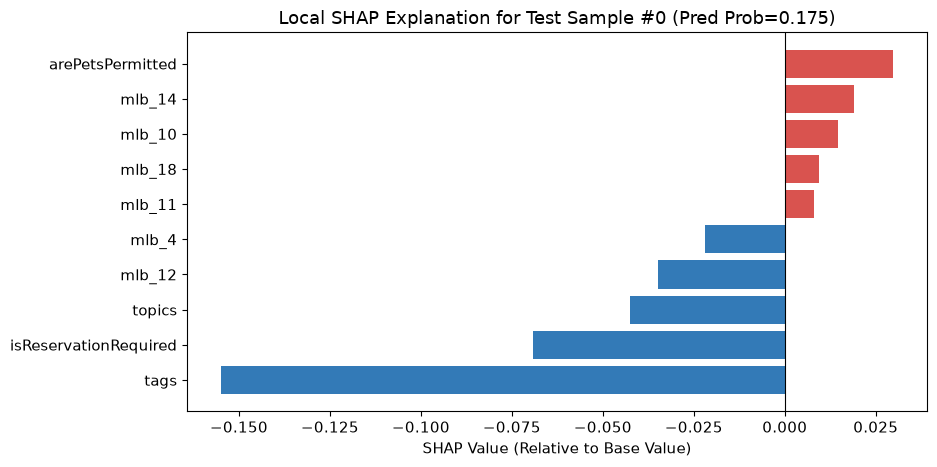

In [32]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

warnings.filterwarnings("ignore", category=UserWarning)


def get_clean_feature_names(preprocessor, X_sample, expected_len):
    names = []
    for name, trans, cols in preprocessor.transformers_:
        col_list = (
            list(cols)
            if isinstance(cols, (list, np.ndarray, tuple, pd.Index))
            else [cols]
        )

        part_out = trans.transform(X_sample[col_list])
        if hasattr(part_out, "toarray"):
            part_out = part_out.toarray()
        n_out = part_out.shape[1] if getattr(part_out, "ndim", 1) > 1 else 1

        if name == "std":
            if n_out == len(col_list):
                names.extend(col_list)
            else:
                names.extend([f"std_{i}" for i in range(n_out)])

        elif name == "remainder":
            if n_out == len(col_list):
                names.extend(col_list)
            else:
                names.extend([f"rem_{i}" for i in range(n_out)])

        elif name == "multilabel":
            names.extend([f"mlb_{i}" for i in range(n_out)])

        else:
            if n_out == len(col_list):
                names.extend(col_list)
            else:
                names.extend([f"{name}_{i}" for i in range(n_out)])

    if len(names) != expected_len:
        return [f"feat_{i}" for i in range(expected_len)]
    return names


best_rf_pipe = rf_best_models[0]
X_test_sample, y_test_sample = rf_test_sets[0]

prep_step = best_rf_pipe.named_steps["preprocessor"]
rf_est = best_rf_pipe.named_steps["model"]

# Transform test features so SHAP aligns with the Random Forest model input
X_test_trans = prep_step.transform(X_test_sample)
if hasattr(X_test_trans, "toarray"):
    X_test_trans = X_test_trans.toarray()
X_test_trans = np.asarray(X_test_trans, dtype=float)

trans_feature_names = get_clean_feature_names(
    prep_step, X_test_sample, expected_len=X_test_trans.shape[1]
)
X_test_trans_df = pd.DataFrame(X_test_trans, columns=trans_feature_names)

# Compute SHAP values for the positive class (class 1)
explainer = shap.TreeExplainer(rf_est)
shap_values_raw = explainer.shap_values(X_test_trans)

if isinstance(shap_values_raw, list):
    shap_pos = np.array(shap_values_raw[1])
    base_val = (
        explainer.expected_value[1]
        if np.ndim(explainer.expected_value) > 0
        else explainer.expected_value
    )
elif np.ndim(shap_values_raw) == 3:
    shap_pos = shap_values_raw[:, :, 1]
    base_val = (
        explainer.expected_value[1]
        if np.ndim(explainer.expected_value) > 0
        else explainer.expected_value
    )
else:
    shap_pos = np.array(shap_values_raw)
    base_val = (
        explainer.expected_value[0]
        if np.ndim(explainer.expected_value) > 0
        else explainer.expected_value
    )

base_val = float(np.asarray(base_val).reshape(-1)[0])

# 1. Global Mean Absolute SHAP
mean_abs_shap = pd.Series(
    np.abs(shap_pos).mean(axis=0), index=trans_feature_names
).sort_values(ascending=False)
print("Top 10 Features by Mean Absolute SHAP (mlb_k = binarized sub-features from timeOfDay/season/regions/park_categories):")
display(mean_abs_shap.head(10))

plt.rcParams.update({"font.size": 11})
top_shap = mean_abs_shap.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.barh(top_shap.index, top_shap.values)
ax.set_xlabel("Mean |SHAP value| (Impact on Class 1)")
ax.set_title("Top 10 Global Feature Importance (Mean Absolute SHAP)")
plt.tight_layout()
plt.show()

# 2. Local SHAP explanation for a meaningful single test sample
sample_idx = 0
pred_class = int(rf_est.predict(X_test_trans[[sample_idx]])[0])
pred_prob = float(rf_est.predict_proba(X_test_trans[[sample_idx]])[0, 1])
true_label = int(y_test_sample.iloc[sample_idx])

sample_shap = pd.Series(shap_pos[sample_idx], index=trans_feature_names)
sample_contrib_df = pd.DataFrame({
    "Feature_Value": X_test_trans[sample_idx],
    "SHAP_Value": sample_shap.values,
    "Direction": ["Push Higher (+)" if v > 0 else "Push Lower (-)" for v in sample_shap.values],
}, index=trans_feature_names)

print(
    f"Sample Index: {sample_idx} | True Label: {true_label} | Predicted Class: {pred_class} | Predicted Prob(1): {pred_prob:.4f}"
)
print(f"SHAP Base Value (reference): {base_val:.4f} | Sum of SHAP: {sample_shap.sum():.4f}")
print("\nTop features pushing prediction HIGHER:")
display(sample_contrib_df.sort_values("SHAP_Value", ascending=False).head(5))
print("\nTop features pushing prediction LOWER:")
display(sample_contrib_df.sort_values("SHAP_Value", ascending=True).head(5))

# Plot local waterfall / bar explanation for the chosen sample
top_local = pd.concat([
    sample_contrib_df.sort_values("SHAP_Value", ascending=False).head(5),
    sample_contrib_df.sort_values("SHAP_Value", ascending=True).head(5),
]).sort_values("SHAP_Value", ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
colors_local = ["#d9534f" if v > 0 else "#337ab7" for v in top_local["SHAP_Value"]]
ax.barh(top_local.index, top_local["SHAP_Value"], color=colors_local)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("SHAP Value (Relative to Base Value)")
ax.set_title(f"Local SHAP Explanation for Test Sample #{sample_idx} (Pred Prob={pred_prob:.3f})")
plt.tight_layout()
plt.show()